# F1 Race Position Prediction Model
**Module:** `notebooks/04_race_prediction.ipynb`  
**Contributor:** Arya Sankhalkar (Member 4 - ML Lead)  
**Task:** Train a Random Forest Regressor to predict each driver's **lap-by-lap position** from lap, tyre and weather data, and test how well it works on races it has never seen.

#### Technical Implementation
* **Data Source:** `data/processed/cleaned_laps.csv`
* **Features:** `LapNumber`, `Stint`, `TyreLife`, `LapTime_s`, `AirTemp`, `TrackTemp`
* **Target Variable:** `Position` (the driver's position at the end of each lap)
* **Model:** Scikit-Learn `RandomForestRegressor` (`n_estimators=100`)
* **Evaluation:** MAE, RMSE and $R^2$, using two different train/test splits
* **Code:** model functions are in `src/race_model.py`

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure src module can be imported
sys.path.append(os.path.abspath('../src'))
from race_model import load_data, prepare_features, train_race_model_group_split

# Load data and build the feature matrix
df = load_data('../data/processed/cleaned_laps.csv')
X, y, groups, features = prepare_features(df)

print(f"Features selected: {features}")
print(f"Target variable: Position")
print(f"Total laps: {len(X)} | Races: {groups.nunique()}")

Features selected: ['LapNumber', 'Stint', 'TyreLife', 'LapTime_s', 'AirTemp', 'TrackTemp']
Target variable: Position
Total laps: 5305 | Races: 5


## 1. Naive baseline: random lap split
Laps are shuffled randomly into 80% training and 20% testing. Because neighbouring laps of the same driver are almost identical, laps from the same race end up in both sets. This lets the model "look up" answers from nearby laps, so the score is expected to be too optimistic.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_random = RandomForestRegressor(n_estimators=100, random_state=42)
rf_random.fit(X_train, y_train)
y_pred = rf_random.predict(X_test)

random_metrics = {
    'MAE': mean_absolute_error(y_test, y_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'R2': r2_score(y_test, y_pred)
}
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")
for metric, score in random_metrics.items():
    print(f"  {metric}: {score:.2f}")

Training samples: 4244 | Testing samples: 1061
  MAE: 2.37
  RMSE: 3.16
  R2: 0.67


## 2. Honest evaluation: race-based split (LeaveOneGroupOut)
The model is trained on 4 races and tested on the 5th, repeated so every race is tested once. The model never sees any lap from the race it is tested on, which matches the real use case of predicting a new Grand Prix.

In [3]:
model, group_metrics = train_race_model_group_split(X, y, groups)

for metric, score in group_metrics.items():
    print(f"  {metric}: {score:.2f}")

  MAE: 5.86
  RMSE: 7.13
  R2: -0.71


In [4]:
comparison = pd.DataFrame({
    'Random lap split': random_metrics,
    'Race-based split': group_metrics
}).T.astype(float).round(2)
comparison

,MAE,RMSE,R2
Random lap split,2.37,3.16,0.67
Race-based split,5.86,7.13,-0.71


## 3. Feature importances
Importances from the final model trained on all laps. They show which inputs the model relies on, **not** what decides a driver's position in real races, because the model does not generalise to new races (see section 2).

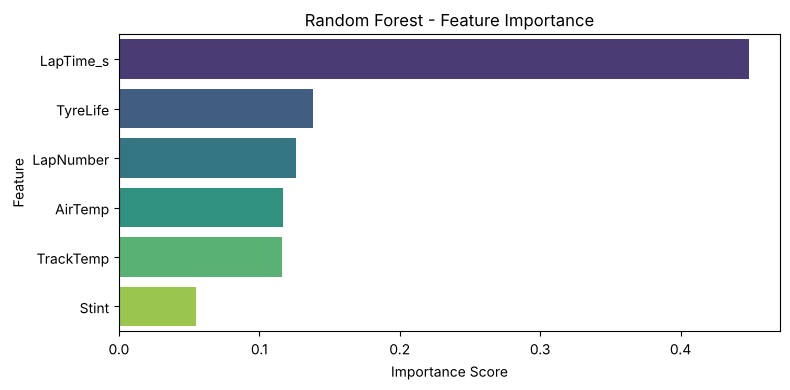

,Feature,Importance
3,LapTime_s,0.448
2,TyreLife,0.138
0,LapNumber,0.126
4,AirTemp,0.116
5,TrackTemp,0.116
1,Stint,0.055


In [5]:
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=importance_df, palette='viridis', legend=False)
plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

importance_df.round(3)

## Conclusions & Findings
- **The random split is misleading.** With laps shuffled randomly, the model scores MAE 2.37 positions and $R^2$ = 0.67.
- **On unseen races, the model fails.** With the race-based split, MAE rises to 5.86 positions and $R^2$ drops to −0.71, which is worse than always guessing the average position.
- **Why:** neighbouring laps of the same driver are almost identical, so with a random split the model can copy answers from laps it has already seen. Air temperature and track temperature (together about 23% of the importance) mostly identify *which race* a lap is from, which helps memorisation but not prediction.
- **Lap time is the strongest input** (about 45% of the importance), followed by tyre age and lap number.

### Limitations
- Only 5 races, so the model has very few different races to learn from.
- The features describe a single lap, while position depends on the whole race so far (starting position, pit stops, overtakes).

### Possible improvements
- Predict **finishing position** with one row per driver per race, using grid position, pit stops and race pace as features.
- Use more races from the 2025 season.